# Synthetic parameter recovery on PAT16 anatomy

Estimate **four separate, jointly fitted parameters** from synthetic longitudinal observations on the real pre-operative PAT16 tissue geometry and dMRI directions:

| Parameter | Known generating value | Meaning |
|---|---:|---|
| $D_{WM}$ | 0.500 mm²/day | WM mean tumor-cell migration diffusivity |
| $D_{GM}$ | 0.100 mm²/day | GM tumor-cell migration diffusivity |
| $\rho$ | 0.040 day⁻¹ | Shared logistic proliferation rate |
| $r$ | 2.500 | Eligible WM parallel/perpendicular migration ratio |

**Run All** in the locked project environment to replay the checked recorded results. Set **RERUN = True** below to generate and refit observations, or use the headless runner. The full audit fits scans at days **20, 40, 60** and withholds **75, 90**; it uses **100 parametric bootstrap fits** and **60 independent noise trials**. A further recorded prediction audit compares 20,000 noisy draws with Gaussian-noise integration and refits 40 independent datasets, each with 100 new bootstrap fits. The original recovery takes several minutes; the nested predictive audit is a separate, longer headless run (`scripts/run_pat16_prediction.py`). The original [PAT16 pilot](pat16_anisotropic_pilot.ipynb) remains a separate assumed-parameter sensitivity experiment.

The observations here are **generated cellularity proxies**, not measured patient tumor signals. Known initialization, anatomy, directions and imaging calibration make this a conditional recovery and uncertainty audit. It does not estimate this patient's biological rates or validate a clinical forecast. See [the recovery guide](examples/pat16_recovery.md).


In [1]:
from pathlib import Path
import os, sys, json
from dataclasses import asdict
ROOT = Path.cwd()
if not (ROOT / 'src/brainweb_kpp').is_dir():
    raise RuntimeError('Start Jupyter from the brainweb_fisher_kpp directory.')
sys.path.insert(0, str(ROOT / 'src'))
os.environ.setdefault('MPLCONFIGDIR', '/tmp/brainweb-mpl')
from IPython.display import display, Markdown, Image
import numpy as np
from brainweb_kpp.pat16 import find_source, load_pilot, sha256
from brainweb_kpp.pat16_inference import PAT16RecoveryDesign
from brainweb_kpp.pat16_recovery import PAT16RecoverySettings, run_pat16_recovery

OUTPUT = ROOT / 'outputs/pat16_recovery'
SETTINGS = PAT16RecoverySettings()  # 100 bootstrap fits; 60 independent noise trials
DESIGN = PAT16RecoveryDesign()     # Full 3 mm anatomy; 72 mm observation cube
RERUN = False  # True refits; False replays checked records
print(json.dumps(asdict(SETTINGS), indent=2))

{
  "known_parameters": [
    0.5,
    0.1,
    0.04,
    2.5
  ],
  "scan_days": [
    20.0,
    40.0,
    60.0,
    75.0,
    90.0
  ],
  "training_scans": 3,
  "noise_sd": 0.015,
  "n_bootstrap": 100,
  "n_coverage": 60,
  "seed": 161026,
  "confidence": 0.95,
  "near_center_radius_mm": 24.0,
  "starts": [
    [
      0.25,
      0.2,
      0.025,
      1.5
    ],
    [
      0.4,
      0.15,
      0.035,
      2.0
    ],
    [
      0.8,
      0.05,
      0.065,
      3.2
    ]
  ]
}


## Forward model, observation operator and fitting

The full PAT16 tissue domain evolves with the same conservative 19-point tensor stencil and blocked-corner/no-flux boundaries as the pilot. The migration tensor in eligible WM is

$$D(x)=\frac{3D_{WM}}{r+2}\left[I+(r-1)v(x)v(x)^T\right].$$

Its local mean diffusivity is $D_{WM}$ for every $r$. GM and WM without valid directions remain isotropic. The two tissue rates have no fixed ratio or imposed ordering. The tensor family assumes prolate migration ($r\ge1$); its upper search bound 3.5 is imposed for stencil monotonicity. Measured water diffusion magnitudes are not tumor migration rates, and fMRI does not enter the likelihood.

The known initial density uses the lesion mask at threshold 0.5, Gaussian smoothing of 0.7 simulation voxels and amplitude 0.6. The **fixed 72 mm observation cube** is centered on the initial lesion centroid before generating or fitting observations. A 2 mm Gaussian blur precedes 6 mm voxel averaging with $3^3$ midpoint quadrature samples. Independent Gaussian noise with **known SD 0.015** is added after imaging, with no clipping. The normalized signal is an assumed calibrated proxy. Uniform capacity cancels in $u=c/K$; capacity and absolute cell counts are not identified.

The generator uses a **0.25-day step** and inversion uses **0.5 day** on the same 3 mm anatomy. Optimization minimizes known-noise Gaussian residuals in $(\log D_{WM},\log D_{GM},\log\rho,\log r)$ using three starts. Local confidence intervals invert the full-rank Jacobian information. Boundary optima are flagged; their Wald intervals cannot be treated as calibrated. Time-zero-only inference is rejected. Float64 snapshots preserve likelihood-derivative accuracy.


In [2]:
if RERUN:
    SOURCE = find_source()  # Or find_source('/absolute/path/to/processed/project')
    pilot = load_pilot(SOURCE, spacing=3.)
    print('Real PAT16 anatomy:', pilot.mask.shape, '; active tissue voxels:', int(pilot.mask.sum()))
    summary, arrays = run_pat16_recovery(pilot, OUTPUT, design=DESIGN, settings=SETTINGS,
                                        progress=lambda message: print(message, flush=True))
else:
    provenance = json.loads((OUTPUT / 'provenance.json').read_text())
    for name, expected in provenance['software_sha256'].items():
        if sha256(ROOT / 'src/brainweb_kpp' / name) != expected:
            raise RuntimeError(f'Stale recovery code: {name}; rerun the audit.')
    for name, expected in provenance['outputs_sha256'].items():
        if sha256(OUTPUT / name) != expected:
            raise RuntimeError(f'Stale recovery output: {name}; rerun the audit.')
    summary = json.loads((OUTPUT / 'summary.json').read_text())
    with np.load(OUTPUT / 'recovery_data.npz') as saved:
        arrays = {key: saved[key] for key in saved.files}
    sys.path.insert(0, str(ROOT / 'paper'))
    from make_pat16_recovery_figures import load_records
    from make_pat16_prediction_figures import verify_records, overlay_primary
    summary, arrays = load_records()
    prediction_summary, primary_prediction = verify_records(summary, arrays)
    overlay_primary(summary, arrays, prediction_summary, primary_prediction)
    print('Replaying checked recovery and nested predictive records; no new parameter fits were performed.')


Replaying checked recovery and nested predictive records; no new parameter fits were performed.


## Parameter estimates and uncertainty

Local 95% Wald intervals use the known observation noise variance; they are not rescaled by the realized residual variance. Bootstrap datasets are generated from the **fitted early-scan model**, then refitted. The empirical 2.5th/97.5th percentiles form marginal 95% intervals. No known parameter is used to center these resamples, and no later scan enters optimization or resampling. These are frequentist conditional intervals, not Bayesian posterior distributions.

All four parameters, their correlations, boundary flags, and whether each interval contains the generating value are reported. A single successful interval check does not establish coverage.


| Parameter | Known | Estimate | Error (%) | Local 95% CI | Bootstrap 95% CI | Contains known (local / boot) |
|---|---:|---:|---:|---|---|---|
| D_WM_mm2_day | 0.5 | 0.504441 | +0.888 | [0.484292, 0.525427] | [0.486119, 0.526465] | True / True |
| D_GM_mm2_day | 0.1 | 0.102091 | +2.091 | [0.0979992, 0.106354] | [0.0988179, 0.106307] | True / True |
| rho_per_day | 0.04 | 0.039976 | -0.060 | [0.0398444, 0.0401081] | [0.0398612, 0.040126] | True / True |
| parallel_perpendicular | 2.5 | 2.58576 | +3.430 | [2.42414, 2.75816] | [2.45354, 2.75819] | True / True |

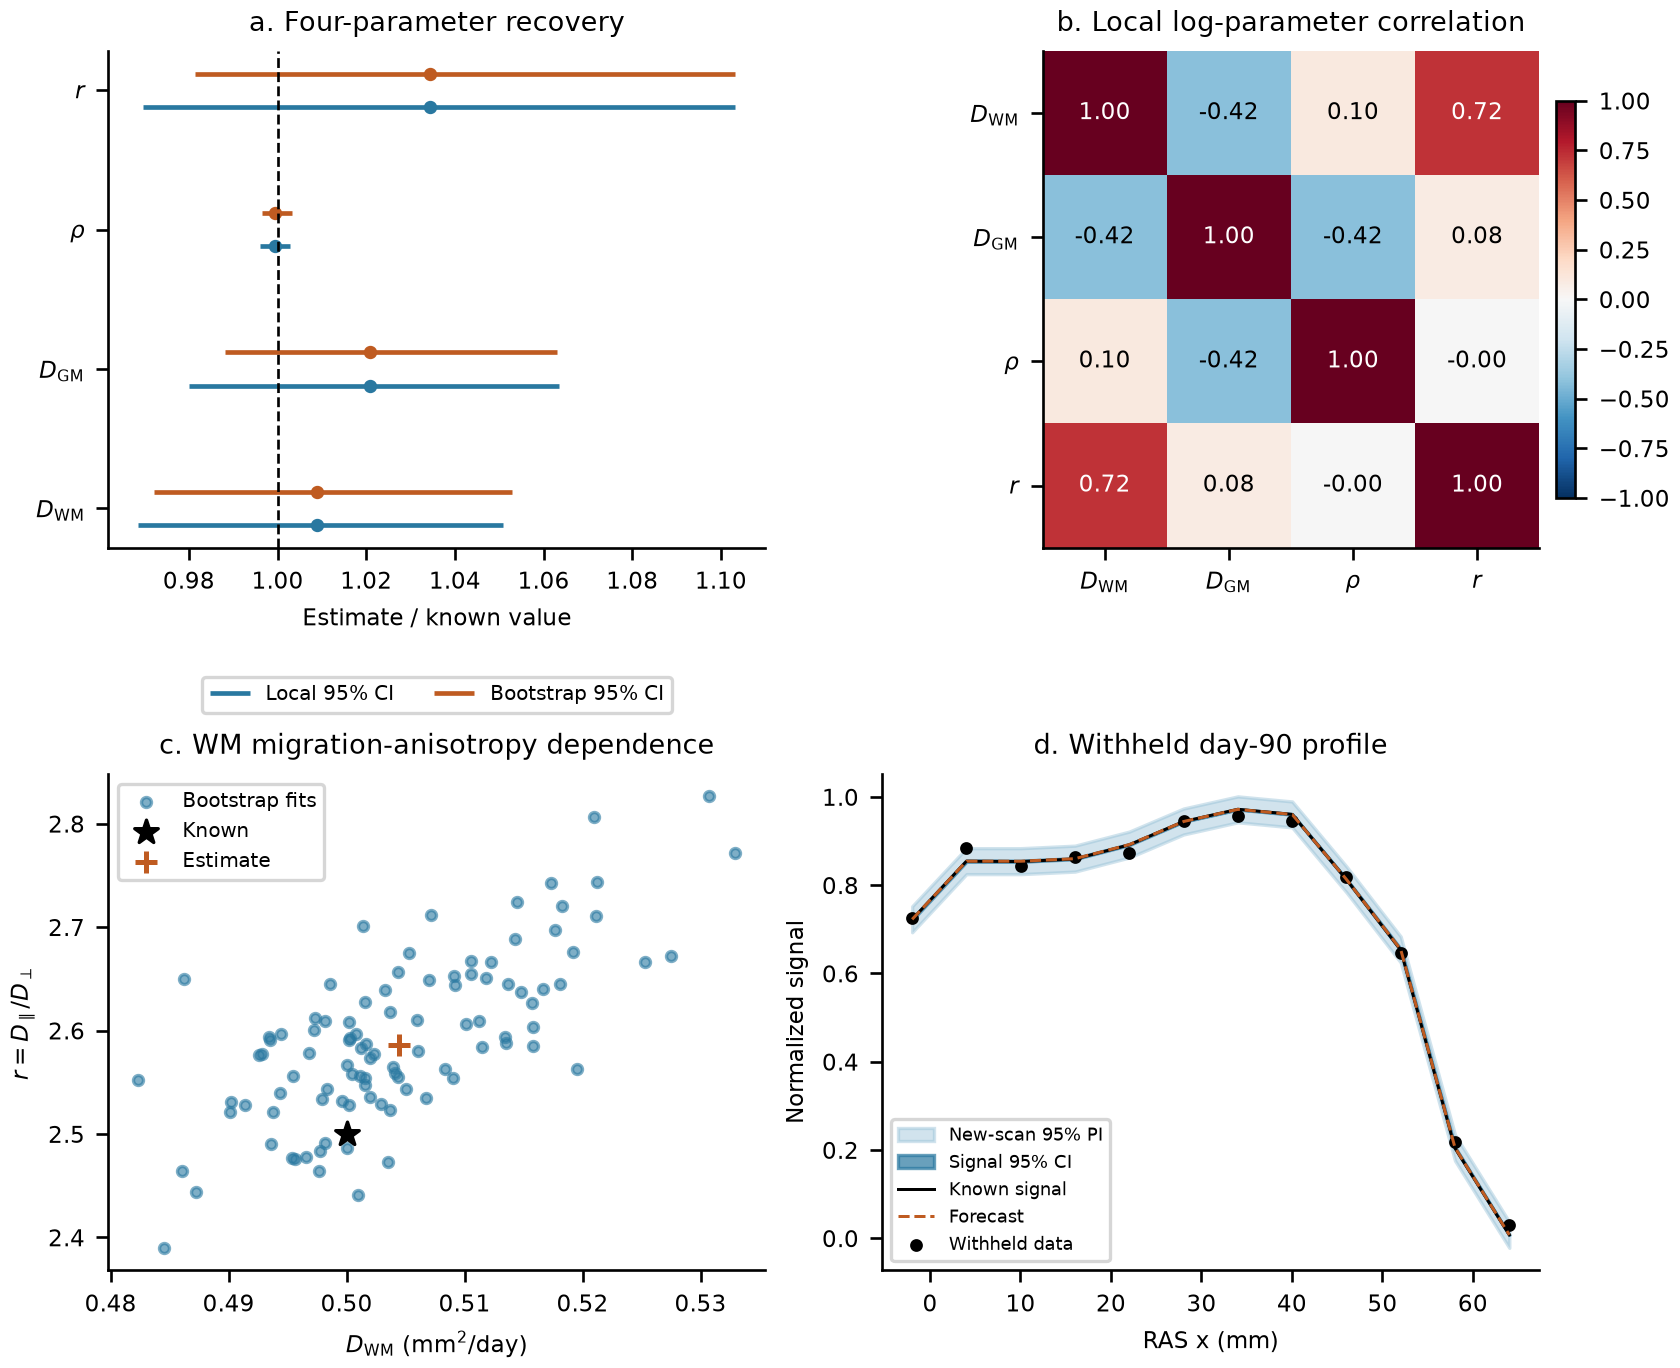

Jacobian condition number: 24.711265293741754
Boundary optimum: False
Multistart estimates: [[0.5044405539672416, 0.10209121100538028, 0.03997603535944493, 2.5857622674881764], [0.5044398425668178, 0.10209141154782908, 0.03997603436331646, 2.585764452456843], [0.5044402985710288, 0.10209135275857915, 0.03997603486743313, 2.5857670243959423]]
Bootstrap successes / boundary fits: 100 / 0


In [3]:
rows = ['| Parameter | Known | Estimate | Error (%) | Local 95% CI | Bootstrap 95% CI | Contains known (local / boot) |',
        '|---|---:|---:|---:|---|---|---|']
for row in summary['parameters']:
    local, boot = row['local_interval'], row['bootstrap_interval']
    rows.append(f"| {row['parameter']} | {row['known']:.6g} | {row['estimate']:.6g} | {row['relative_error_percent']:+.3f} | [{local[0]:.6g}, {local[1]:.6g}] | [{boot[0]:.6g}, {boot[1]:.6g}] | {row['local_contains_known']} / {row['bootstrap_contains_known']} |")
display(Markdown('\n'.join(rows)))
display(Image(filename=str(OUTPUT / 'parameter_recovery.png' if RERUN else ROOT / 'paper/figures/pat16_recovery.png')))
print('Jacobian condition number:', summary['jacobian_condition_number'])
print('Boundary optimum:', summary['at_bound'])
print('Multistart estimates:', [f['estimate'] for f in summary['multistart']])
print('Bootstrap successes / boundary fits:', summary['bootstrap_successful'], '/', summary['bootstrap_boundary_fits'])


## Independent known-value validation

Each of the 60 independent datasets receives fresh noise on signals generated at the **known** parameters and finer time step. This audits bias, RMSE and the **local** confidence intervals. Exact binomial intervals show Monte Carlo uncertainty in estimated coverage. Every attempted trial stays in the denominator; failed fits and boundary Wald intervals count as misses. All failures and boundary counts are saved. This experiment does not audit marginal bootstrap parameter-interval coverage.

A separate **noise-free matched-model fit** must recover all four known values within a maximum relative error of $10^{-4}$. A noise-free finer-time fit reports systematic shifts from temporal mismatch. Sharing spatial anatomy, the stencil and initialization makes this a controlled implementation audit, not independent model or spatial convergence validation.


| Parameter | Trial mean | Bias (%) | RMSE | Local coverage | Exact 95% binomial CI |
|---|---:|---:|---:|---:|---|
| D_WM_mm2_day | 0.502668 | +0.534 | 0.0104196 | 59/60 | [0.911, 1.000] |
| D_GM_mm2_day | 0.0991814 | -0.819 | 0.00243332 | 55/60 | [0.816, 0.972] |
| rho_per_day | 0.0399833 | -0.042 | 7.50631e-05 | 56/60 | [0.838, 0.982] |
| parallel_perpendicular | 2.51086 | +0.434 | 0.0896044 | 55/60 | [0.816, 0.972] |

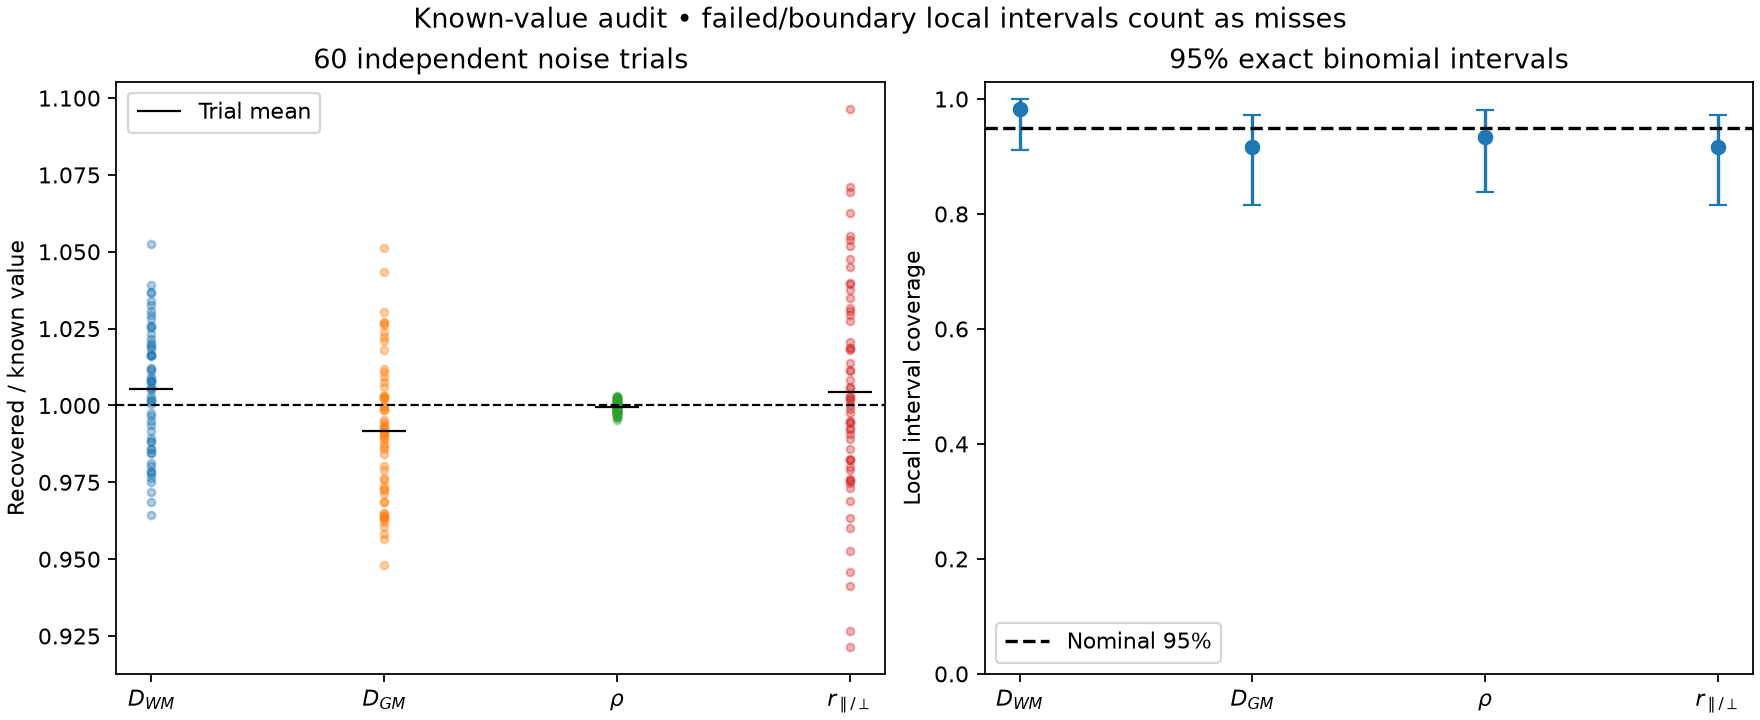

{
  "matched_model_noiseless_estimate": [
    0.5000000000000001,
    0.10000000000000006,
    0.039999999999999813,
    2.500000000000002
  ],
  "matched_model_max_relative_error": 4.6629367034256575e-15,
  "finer_time_noiseless_estimate": [
    0.499563976858324,
    0.09969101041186468,
    0.039963213174192,
    2.497503462519995
  ],
  "finer_time_relative_parameter_shift_percent": [
    -0.08720462833520237,
    -0.3089895881353222,
    -0.09196706452000436,
    -0.09986149920019338
  ],
  "generator_minus_inverse_rmse_by_scan": [
    8.085918605698184e-05,
    0.00015840234156403298,
    0.00022536691735501285,
    0.00026135993681581607,
    0.0002831490966929879
  ],
  "time_zero_negative_control": "WM diffusion, GM diffusion, proliferation and anisotropy are not locally identifiable",
  "limitation": "Generator and inverse share spatial anatomy, stencil and initialization; half time step is a temporal sensitivity check, not spatial convergence or independent biological valida

In [4]:
rows = ['| Parameter | Trial mean | Bias (%) | RMSE | Local coverage | Exact 95% binomial CI |',
        '|---|---:|---:|---:|---:|---|']
for row in summary['parameters']:
    ci = row['local_coverage_binomial_interval']
    rows.append(f"| {row['parameter']} | {row['noise_trial_mean']:.6g} | {row['noise_trial_bias_percent']:+.3f} | {row['noise_trial_rmse']:.6g} | {row['local_coverage_hits']}/{row['local_coverage_trials']} | [{ci[0]:.3f}, {ci[1]:.3f}] |")
display(Markdown('\n'.join(rows)))
display(Image(filename=str(OUTPUT / 'validation.png')))
print(json.dumps(summary['numerical_validation'], indent=2))
print('Fit failures:', summary['failures'])
print('Coverage boundary fits:', summary['coverage_boundary_fits'])


## Withheld forecasts

Days 75 and 90 are withheld from fitting and bootstrap estimation. Each bootstrap parameter vector predicts these scans. Pointwise **signal intervals** propagate parameter uncertainty; final **prediction intervals** integrate known Gaussian observation noise over 100 bootstrap forecast means. A 20,000-draw comparison checks convergence to this mixture. More noise draws improve predictive tails without adding distinct parameter vectors. Report RMSE against the noise-free known signal and normalized RMSE against noisy held-out scans. Interval containment fractions are shown for both the full cube and a prespecified 24 mm sphere around its center. These spatial fractions are descriptive; they are not independent repeated-trial coverage estimates.


**Full observation cube**

| Withheld day | Signal RMSE | Noisy RMSE / SD | Truth in signal interval | Observation in prediction interval |
|---:|---:|---:|---:|---:|
| 75 | 0.000583816 | 0.999 | 0.979 | 0.948 |
| 90 | 0.000661561 | 1.001 | 0.988 | 0.955 |

**Near-center sphere**

| Withheld day | Signal RMSE | Noisy RMSE / SD | Truth in signal interval | Observation in prediction interval |
|---:|---:|---:|---:|---:|
| 75 | 0.000580016 | 1.014 | 0.993 | 0.936 |
| 90 | 0.000486236 | 0.969 | 1.000 | 0.957 |

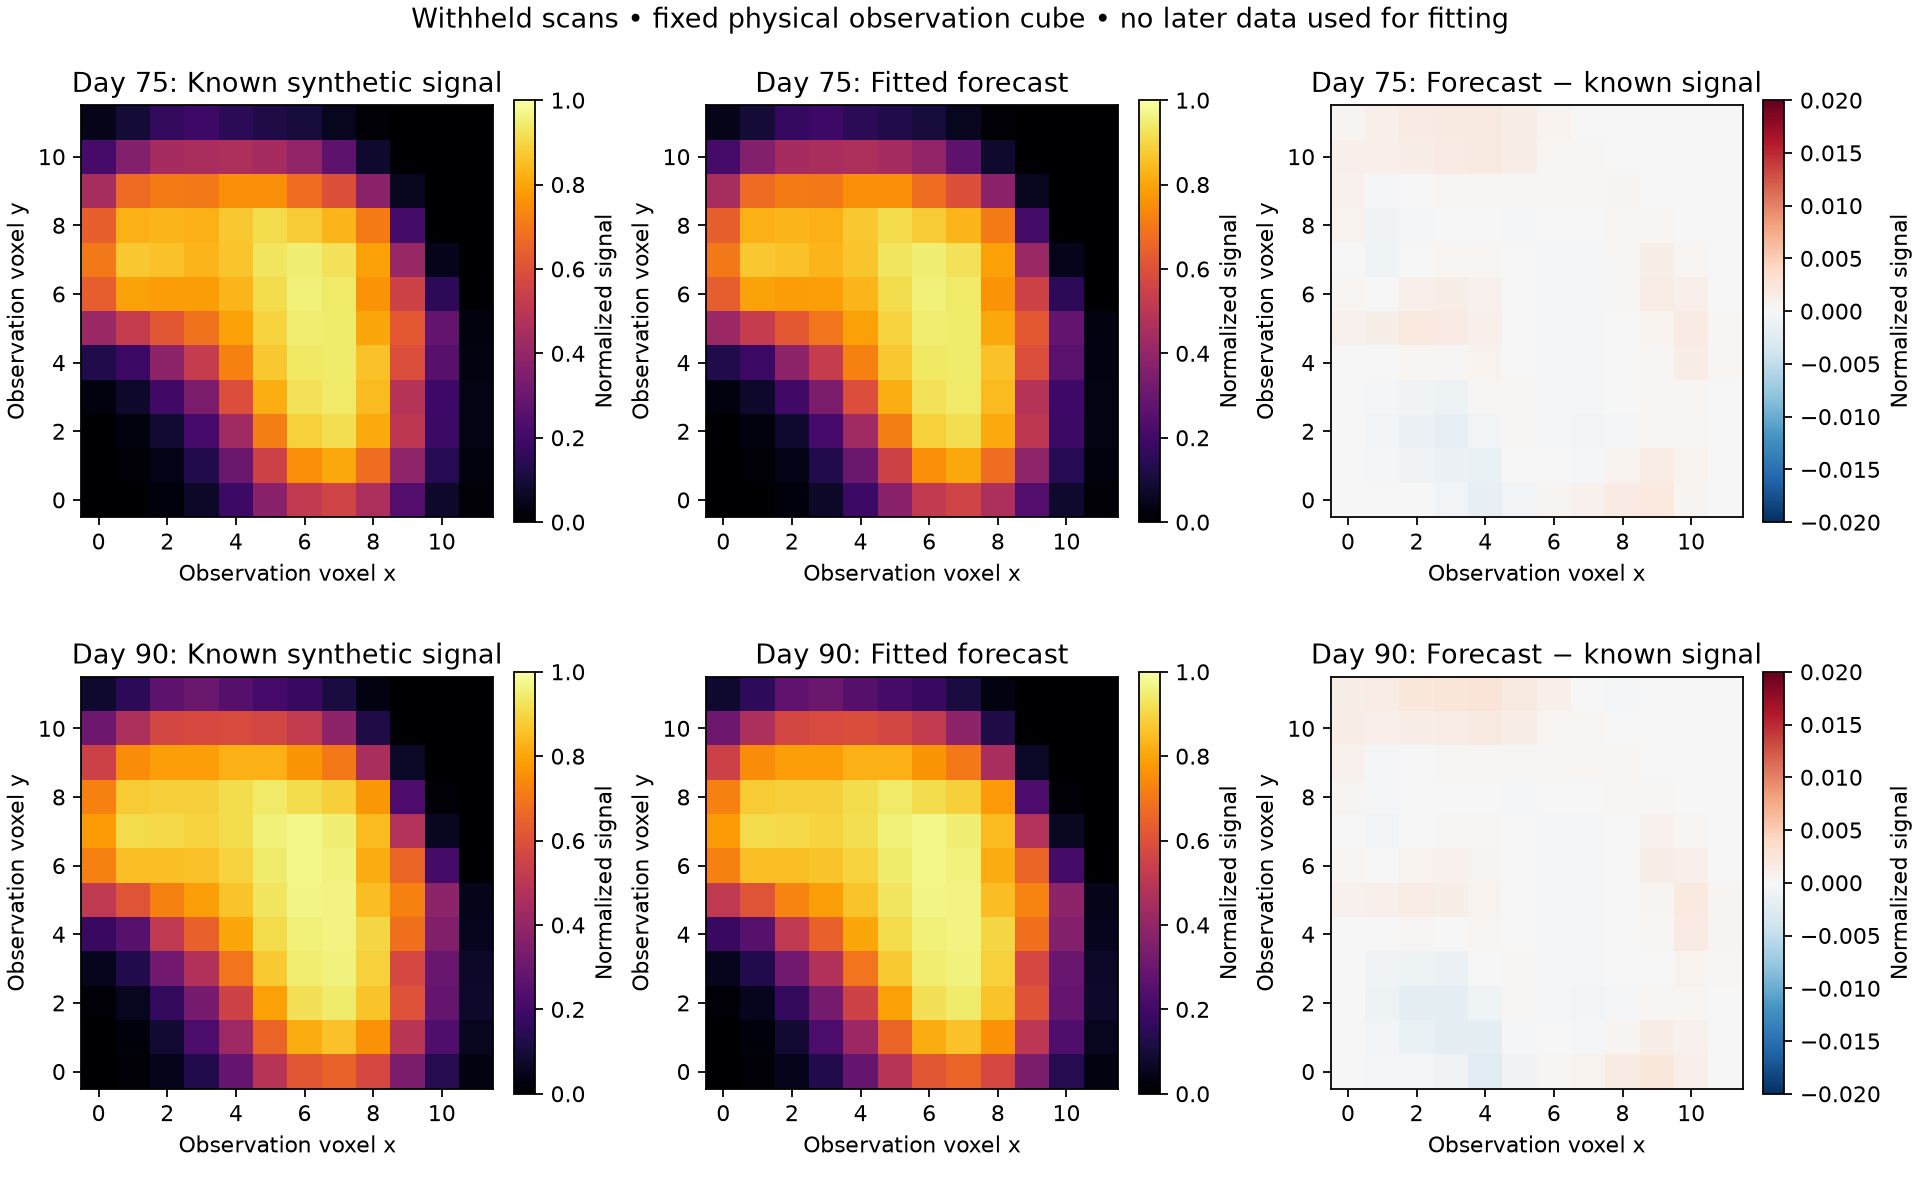

In [5]:
for key, label in [('forecast_full_region', 'Full observation cube'), ('forecast_near_center', 'Near-center sphere')]:
    display(Markdown('**' + label + '**'))
    rows = ['| Withheld day | Signal RMSE | Noisy RMSE / SD | Truth in signal interval | Observation in prediction interval |',
            '|---:|---:|---:|---:|---:|']
    for row in summary[key]:
        rows.append(f"| {row['day']:g} | {row['truth_rmse']:.6g} | {row['observation_rmse_over_noise_sd']:.3f} | {row['signal_interval_truth_fraction']:.3f} | {row['prediction_interval_observation_fraction']:.3f} |")
    display(Markdown('\n'.join(rows)))
display(Image(filename=str(OUTPUT / 'withheld_forecast.png')))


## Repeated prediction-interval coverage

The predictive audit uses **40 independent complete datasets**, each with a fresh four-parameter fit and **100 new parametric bootstrap fits**. Future noise is independent of training and resampling. All three methods use the same bootstrap forecasts in each trial: 100 noisy draws, 20,000 noisy draws and Gaussian-mixture quantiles. No withheld observations tune interval widths or tails.

Coverage is averaged spatial containment across independently refitted datasets, with dataset-level Student-t Monte Carlo 95% limits. Within-image voxels are not independent fit replicates. A prespecified central voxel has exact binomial limits. Width and the proper 95% interval score (width plus miss-distance penalties) accompany coverage. These checks concern the fixed synthetic model, not simultaneous image coverage or patient calibration.


| Method | Day | Region | Mean coverage | MC 95% interval | Mean width | Interval score |
|---|---:|---|---:|---|---:|---:|
| legacy_100 | 75 | full | 93.37% | [93.22, 93.53]% | 0.05644 | 0.07251 |
| legacy_100 | 90 | full | 93.32% | [93.14, 93.50]% | 0.05643 | 0.07288 |
| legacy_100 | 75 | near | 93.16% | [92.72, 93.60]% | 0.05654 | 0.07339 |
| legacy_100 | 90 | near | 92.99% | [92.53, 93.45]% | 0.05649 | 0.07408 |
| mc_20000 | 75 | full | 95.13% | [94.99, 95.28]% | 0.05886 | 0.07007 |
| mc_20000 | 90 | full | 95.02% | [94.86, 95.19]% | 0.05889 | 0.07024 |
| mc_20000 | 75 | near | 94.84% | [94.51, 95.17]% | 0.05888 | 0.07023 |
| mc_20000 | 90 | near | 94.72% | [94.31, 95.14]% | 0.05887 | 0.07119 |
| gaussian_mixture | 75 | full | 95.14% | [95.01, 95.28]% | 0.05887 | 0.07008 |
| gaussian_mixture | 90 | full | 95.03% | [94.87, 95.19]% | 0.05890 | 0.07023 |
| gaussian_mixture | 75 | near | 94.91% | [94.59, 95.24]% | 0.05889 | 0.07023 |
| gaussian_mixture | 90 | near | 94.75% | [94.35, 95.15]% | 0.05889 | 0.07114 |

Primary endpoint RMSE (100 / 1,000 / 20,000 draws / integrated): [0.0038326984718669503, 0.0012792469289140923, 0.00027868331177503044, 0.0]
Fixed-voxel binomial coverage: [{'method': 'legacy_100', 'day': 75.0, 'hits': 37, 'trials': 40, 'fraction': 0.925, 'exact_binomial_interval': [0.796135251267101, 0.9842578201489585]}, {'method': 'legacy_100', 'day': 90.0, 'hits': 38, 'trials': 40, 'fraction': 0.95, 'exact_binomial_interval': [0.8308031360405824, 0.9938863534006491]}, {'method': 'mc_20000', 'day': 75.0, 'hits': 39, 'trials': 40, 'fraction': 0.975, 'exact_binomial_interval': [0.8684141415172343, 0.9993672550679505]}, {'method': 'mc_20000', 'day': 90.0, 'hits': 38, 'trials': 40, 'fraction': 0.95, 'exact_binomial_interval': [0.8308031360405824, 0.9938863534006491]}, {'method': 'gaussian_mixture', 'day': 75.0, 'hits': 39, 'trials': 40, 'fraction': 0.975, 'exact_binomial_interval': [0.8684141415172343, 0.9993672550679505]}, {'method': 'gaussian_mixture', 'day': 90.0, 'hits': 38, 'trials

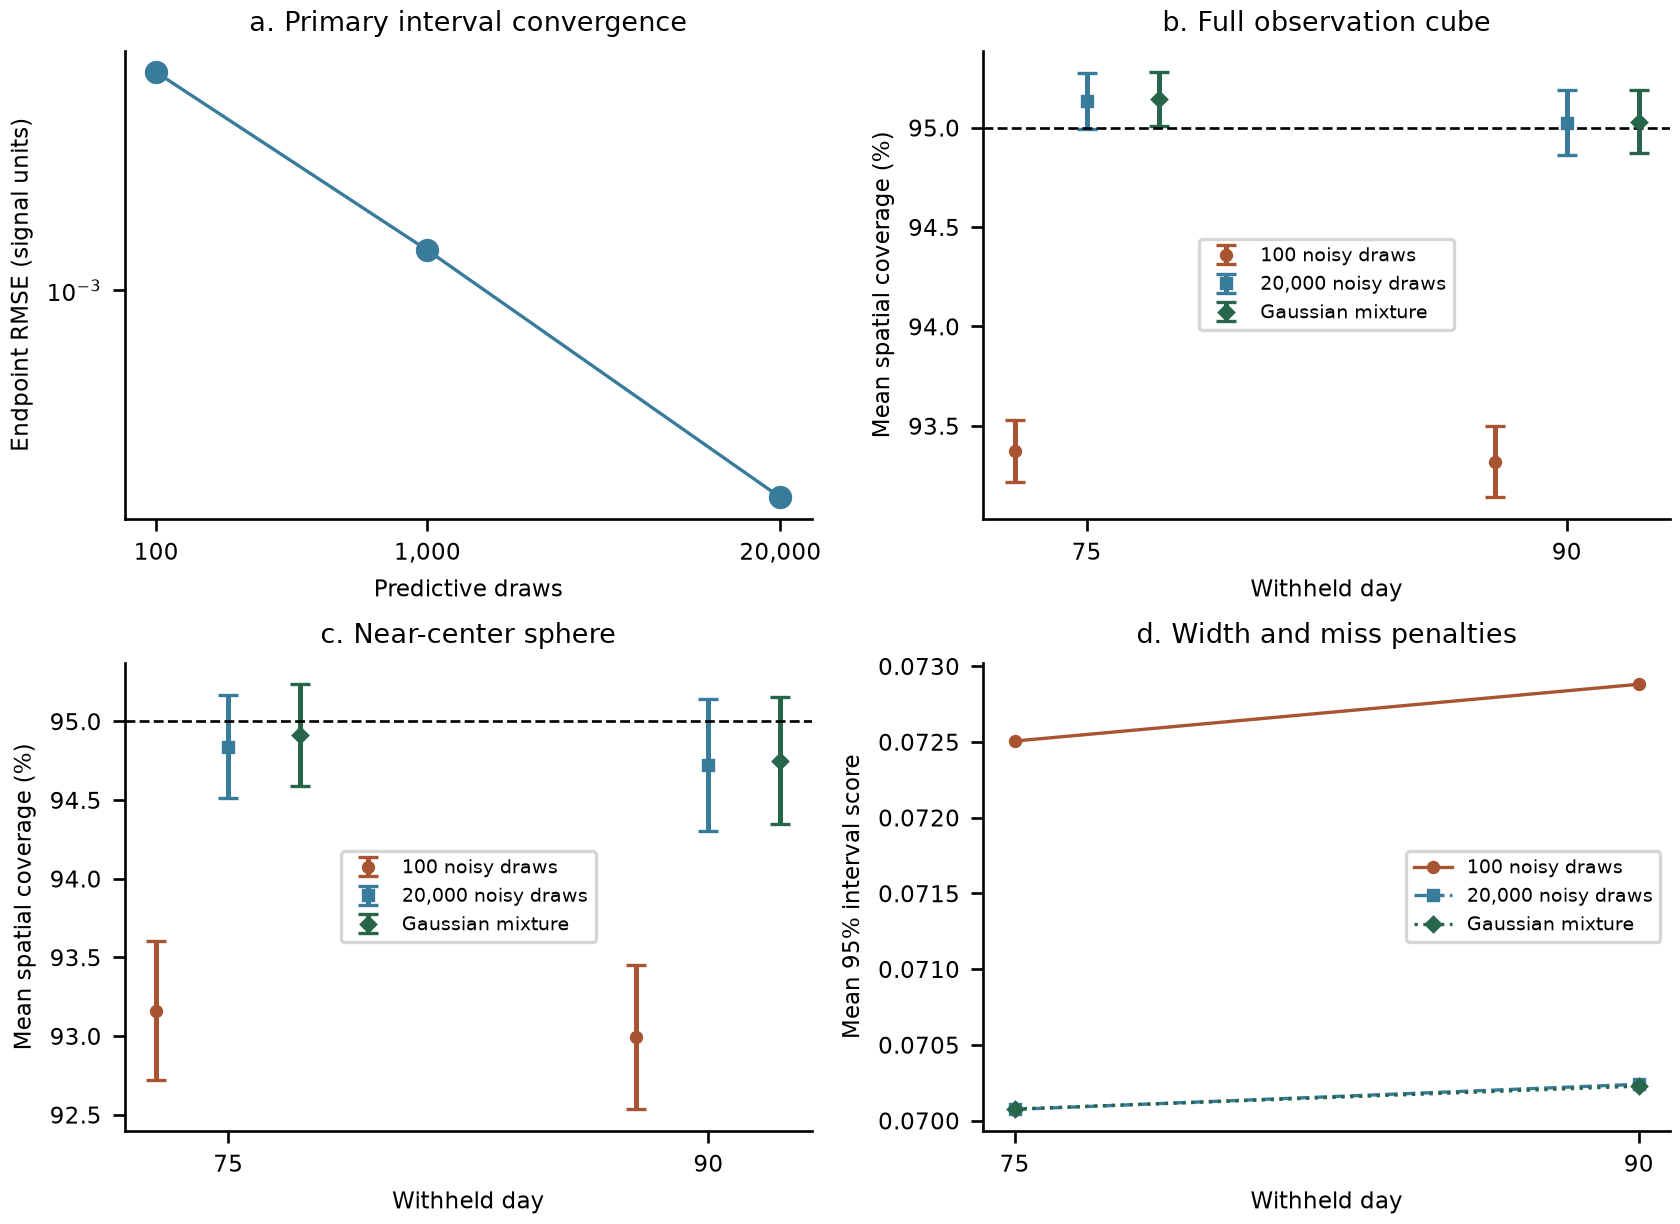

In [6]:
if not RERUN:
    rows = ['| Method | Day | Region | Mean coverage | MC 95% interval | Mean width | Interval score |',
            '|---|---:|---|---:|---|---:|---:|']
    for row in prediction_summary['coverage']:
        ci = row['coverage_mc_interval']
        rows.append(f"| {row['method']} | {row['day']:g} | {row['region']} | {100*row['mean_coverage']:.2f}% | [{100*ci[0]:.2f}, {100*ci[1]:.2f}]% | {row['mean_width']:.5f} | {row['mean_interval_score']:.5f} |")
    display(Markdown('\n'.join(rows)))
    print('Primary endpoint RMSE (100 / 1,000 / 20,000 draws / integrated):', prediction_summary['primary_endpoint_rmse'])
    print('Fixed-voxel binomial coverage:', prediction_summary['sentinel'])
    display(Image(filename=str(ROOT / 'paper/figures/pat16_prediction_validation.png')))
else:
    print('This refit regenerated the original recovery only. Run the separate nested prediction runner to rebuild its audit, using a new output directory if the baseline manifest changed.')


## Saved results and limits

`outputs/pat16_recovery/` contains `summary.json`, `parameters.csv`, `recovery_data.npz`, `provenance.json` and three figures. The NPZ preserves clean/noisy scans, estimates, all bootstrap draws, all independent-noise fits and local intervals, parameter correlations, forecast bands and region masks. The summary retains seeds, bounds, settings, every failure and numerical checks. Provenance records input, source-code and output hashes plus software versions. Raw input MRI is read in place and is not copied.

`outputs/pat16_prediction/` additionally retains primary predictive comparisons, 40 complete trial checkpoints and a hashed manifest. The paper generator validates these records and uses integrated intervals in its forecast figures/tables.

The uncertainty is conditional on fixed anatomy, normalized initialization, directions and imaging/noise calibration. Uniform capacity cancels; absolute capacity is not identified. It does not include segmentation, registration, fiber-direction, initial-state, spatial-discretization or model error. It does not turn a lesion mask into measured cellularity. The PAT16 pre/post-operative pair spans surgery and does not validate untreated growth. Patient inference requires longitudinal calibrated tumor observations and treatment metadata; no patient growth-rate or functional forecast is claimed here.
